# CellRank on the joint devbrain + Brooks object: moscot only

Velocity cannot participate here - Brooks ships no spliced/unspliced counts - so this
notebook runs the kernels that only need an embedding and a time label:
`RealTimeKernel` (moscot OT) and `ConnectivityKernel`.

What it buys over `cellrank_trajectory.ipynb`: the full **nine-stage** timeline
(E7.0, E7.5, E7.75, E8.0, E8.25, E8.5, E8.75, E9.0, E10.0) on a graph that is a single
connected component, which is the setting where asking for a root cell is meaningful.

In [1]:
import os

import numpy as np
import pandas as pd
import scanpy as sc
import cellrank as cr
import matplotlib.pyplot as plt
from moscot.problems.time import TemporalProblem

print("cellrank", cr.__version__)
sc.settings.verbosity = 2
sc.settings.set_figure_params(dpi=100, dpi_save=200, frameon=False, figsize=(5, 5))

base = "/project/imoskowitz/yubin/Trajectory_inference/"
fig_cr = base + "results/figures/08_cellrank_joint/"
res_dir = base + "results/tables/cellrank/"
for d in (fig_cr, res_dir):
    os.makedirs(d, exist_ok=True)
sc.settings.figdir = fig_cr
# plot_macrostates renders through scvelo, which keeps its own figdir. Without
# this, figures go to ./figures/ - which on a compute node is node-local scratch,
# wiped at job end (that is how job 61852175's macrostate plots were lost).
import scvelo as scv
scv.settings.figdir = fig_cr

BASIS = "X_umap_post"
REP = "X_pca_harmony"
N_STATES = 14
N_TERMINAL = 4                  # see predict_terminal_states below

# --- compatibility shim -------------------------------------------------
# scanpy 1.11.5 calls .getnnz() on the kNN distance matrix, but scipy >= 1.16
# hands back a csr_*array* (sparse arrays dropped getnnz), so sc.pp.neighbors
# raises AttributeError. Restore the method rather than pinning scipy, which
# would risk the numpy-2 ABI that petsc4py in this env is built against.
import scipy.sparse as _sp

if not hasattr(_sp.csr_array, "getnnz"):
    def _getnnz(self, axis=None):
        if axis is None:
            return int(self.nnz)
        if axis == 1:
            return np.diff(self.indptr)
        return np.bincount(self.indices, minlength=self.shape[1])
    for _cls in (_sp.csr_array, _sp.csc_array):
        _cls.getnnz = _getnnz
    print("patched sparse-array getnnz for scanpy/scipy compatibility")
# ------------------------------------------------------------------------


def as_sparse_matrices(adata):
    """Force obsp/layers to scipy sparse *matrices*.

    anndata >= 0.12 hands back csr_*arrays*, but scvelo 0.3.4 still uses
    matrix-only APIs (.A1, .getnnz), so it crashes on them. Convert at the
    source instead of patching each call site. Re-run after anything that
    rebuilds these (subsetting, copying).
    """
    from scipy.sparse import csr_matrix, issparse, spmatrix
    for store in (adata.obsp, adata.layers):
        for k in list(store.keys()):
            v = store[k]
            if issparse(v) and not isinstance(v, spmatrix):
                store[k] = csr_matrix(v)
    return adata

cellrank 2.0.7


patched sparse-array getnnz for scanpy/scipy compatibility


In [2]:
adata = sc.read_h5ad(base + "data/processed/devbrain_brooks_integrated.h5ad")
# the joint graph already exists as the "post" neighbours from the integration run
adata.obsp["connectivities"] = adata.obsp["post_connectivities"]
adata.obsp["distances"] = adata.obsp["post_distances"]
adata.uns["neighbors"] = adata.uns["post"]
as_sparse_matrices(adata)
print(adata)
print(adata.obs.groupby(["dataset", "stage"], observed=True).size().to_string())

AnnData object with n_obs × n_vars = 107629 × 15200
    obs: 'sample', 'age', 'tissue', 'leiden', 'dataset', 'stage', 'chip', 'batch_fine', 'celltype_src', 'stage_num', 'Sample ID', 'Batch', 'Cell Type', 'Neural Plate Annotation', 'background_cell', 'dataset_key', 'leiden_joint', 'component'
    var: 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'hvg', 'leiden_joint', 'log1p', 'pca', 'post', 'pre', 'umap', 'neighbors'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap', 'X_umap_post', 'X_umap_pre'
    layers: 'counts'
    obsp: 'post_connectivities', 'post_distances', 'pre_connectivities', 'pre_distances', 'connectivities', 'distances'
dataset   stage
brooks    E7.5      9533
          E7.75     7101
          E8.0      3444
          E8.25     3397
          E8.5     10085
          E8.75     5903
devbrain  E7.0     11195
          E8.0      6813
          E8.5      3241
          E9.0     14781
          E1

## moscot across all nine stages

In [3]:
tp = TemporalProblem(adata)
tp = tp.prepare(time_key="stage_num", joint_attr={"attr": "obsm", "key": REP})
print(tp)

TemporalProblem[(9.0, 10.0), (8.0, 8.25), (8.25, 8.5), (7.0, 7.5), (8.75, 9.0), (7.75, 8.0), (8.5, 8.75), (7.5, 7.75)]


In [4]:
tp = tp.solve(epsilon=1e-2, tau_a=0.95, tau_b=0.95, scale_cost="mean")
for k, v in tp.solutions.items():
    print(f"  {k}: converged={v.converged}  cost={float(v.cost):.4g}")

INFO     Solving `8` problems                                                                                      


INFO     Solving problem BirthDeathProblem[stage='prepared', shape=(14781, 32136)].                                


INFO     Solving problem BirthDeathProblem[stage='prepared', shape=(10257, 3397)].                                 


INFO     Solving problem BirthDeathProblem[stage='prepared', shape=(3397, 13326)].                                 


INFO     Solving problem BirthDeathProblem[stage='prepared', shape=(11195, 9533)].                                 


INFO     Solving problem BirthDeathProblem[stage='prepared', shape=(5903, 14781)].                                 


INFO     Solving problem BirthDeathProblem[stage='prepared', shape=(7101, 10257)].                                 


INFO     Solving problem BirthDeathProblem[stage='prepared', shape=(13326, 5903)].                                 


INFO     Solving problem BirthDeathProblem[stage='prepared', shape=(9533, 7101)].                                  


  (9.0, 10.0): converged=True  cost=0.1467
  (8.0, 8.25): converged=True  cost=0.1145
  (8.25, 8.5): converged=True  cost=0.1487
  (7.0, 7.5): converged=True  cost=0.1491
  (8.75, 9.0): converged=True  cost=0.1646
  (7.75, 8.0): converged=True  cost=0.1479
  (8.5, 8.75): converged=True  cost=0.1388
  (7.5, 7.75): converged=True  cost=0.113


In [5]:
rtk = cr.kernels.RealTimeKernel.from_moscot(tp)
rtk = rtk.compute_transition_matrix(self_transitions="all", conn_weight=0.2)
ck = cr.kernels.ConnectivityKernel(adata).compute_transition_matrix()
print(rtk, "\n", ck)

KERNELS = {
    "joint_realtime":          rtk,
    "joint_rtk0.8_ck0.2":      0.8 * rtk + 0.2 * ck,
    "joint_rtk0.5_ck0.5":      0.5 * rtk + 0.5 * ck,
}

  0%|          | 0/8 [00:00<?, ?time pair/s]

100%|██████████| 8/8 [00:00<00:00, 27302.22time pair/s]

Using automatic `threshold=6.531191196592137e-14`


Computing transition matrix based on `adata.obsp['connectivities']`


    Finish (0:00:00)


RealTimeKernel[n=107629] 
 ConnectivityKernel[n=107629]


joint_realtime


Computing Schur decomposition


Adding `adata.uns['eigendecomposition_fwd']`
       `.schur_vectors`
       `.schur_matrix`
       `.eigendecomposition`
    Finish (0:03:49)


Computing `14` macrostates


!! joint_realtime FAILED: ValueError: Discretizing leads to a cluster with `0` samples, less than the threshold which is `6` samples. Consider recomputing the fuzzy clustering.


...

Adding `adata.obsm['lineages_fwd']`
       `.fate_probabilities`
    Finish (0:07:23)



[0]PETSC ERROR: ------------------------------------------------------------------------
[0]PETSC ERROR: Caught signal number 13 Broken Pipe: Likely while reading or writing to a socket
[0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: to get more information on the crash.


/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:656: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  smp = ax.scatter(


/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:694: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1400: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=bg_size, marker=".", c=bg_color, zorder=zord - 2, **kwargs)
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1401: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=gp_size, marker=".", c=gp_color, zorder=zord - 1, **kwargs)


saving figure to file ./figures/scvelo_joint_rtk0.8_ck0.2_macrostates.png


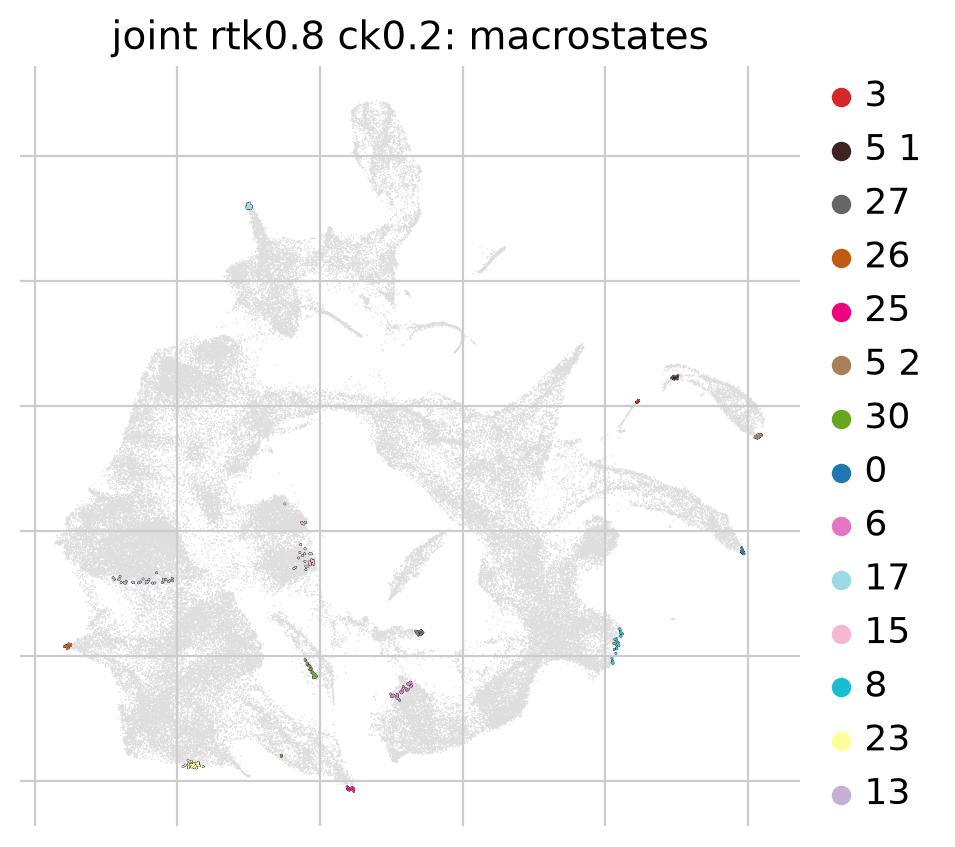

/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:656: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  smp = ax.scatter(


/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:694: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1400: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=bg_size, marker=".", c=bg_color, zorder=zord - 2, **kwargs)
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1401: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=gp_size, marker=".", c=gp_color, zorder=zord - 1, **kwargs)


saving figure to file ./figures/scvelo_joint_rtk0.8_ck0.2_terminal.png


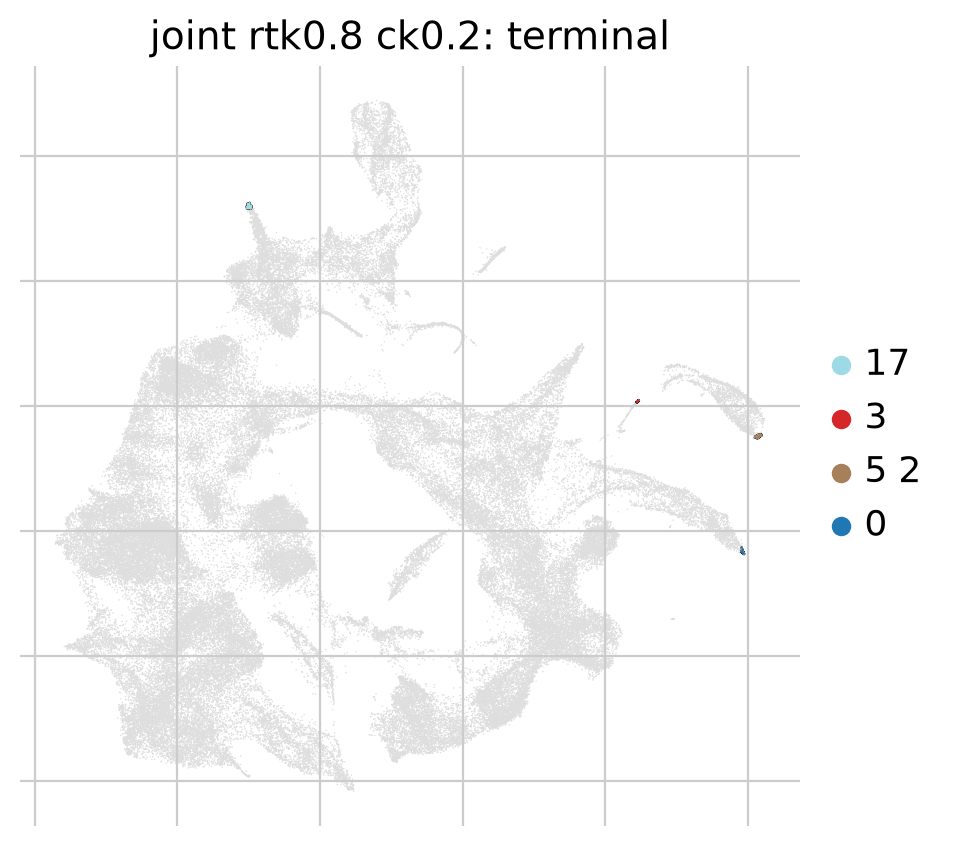

  wrote fate_joint_rtk0.8_ck0.2.csv, composition_*_joint_rtk0.8_ck0.2.csv
joint_rtk0.5_ck0.5


Computing Schur decomposition


When computing macrostates, choose a number of states NOT in `[np.int64(18)]`


Adding `adata.uns['eigendecomposition_fwd']`
       `.schur_vectors`
       `.schur_matrix`
       `.eigendecomposition`
    Finish (0:03:17)


Computing `14` macrostates


...

Adding `adata.obsm['lineages_fwd']`
       `.fate_probabilities`
    Finish (0:07:00)



[0]PETSC ERROR: ------------------------------------------------------------------------
[0]PETSC ERROR: Caught signal number 13 Broken Pipe: Likely while reading or writing to a socket
[0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: to get more information on the crash.
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0


/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:656: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  smp = ax.scatter(


/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:694: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1400: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=bg_size, marker=".", c=bg_color, zorder=zord - 2, **kwargs)
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1401: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=gp_size, marker=".", c=gp_color, zorder=zord - 1, **kwargs)


saving figure to file ./figures/scvelo_joint_rtk0.5_ck0.5_macrostates.png


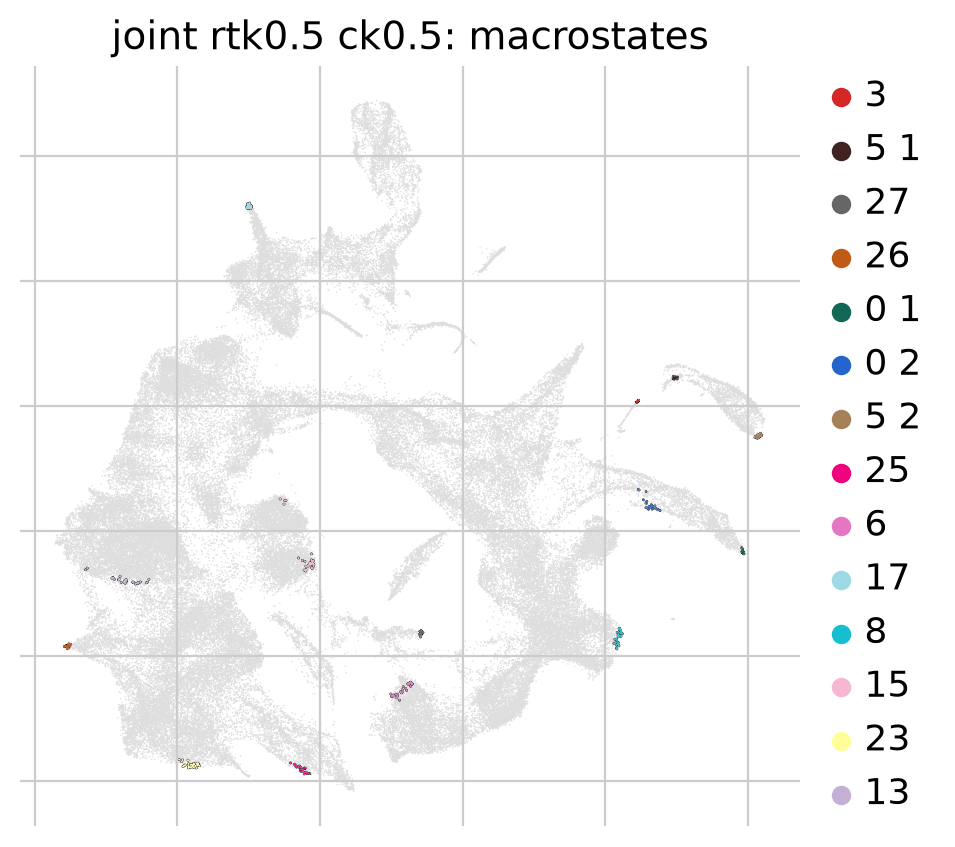

/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:656: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  smp = ax.scatter(


/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:694: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1400: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=bg_size, marker=".", c=bg_color, zorder=zord - 2, **kwargs)
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1401: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=gp_size, marker=".", c=gp_color, zorder=zord - 1, **kwargs)


saving figure to file ./figures/scvelo_joint_rtk0.5_ck0.5_terminal.png


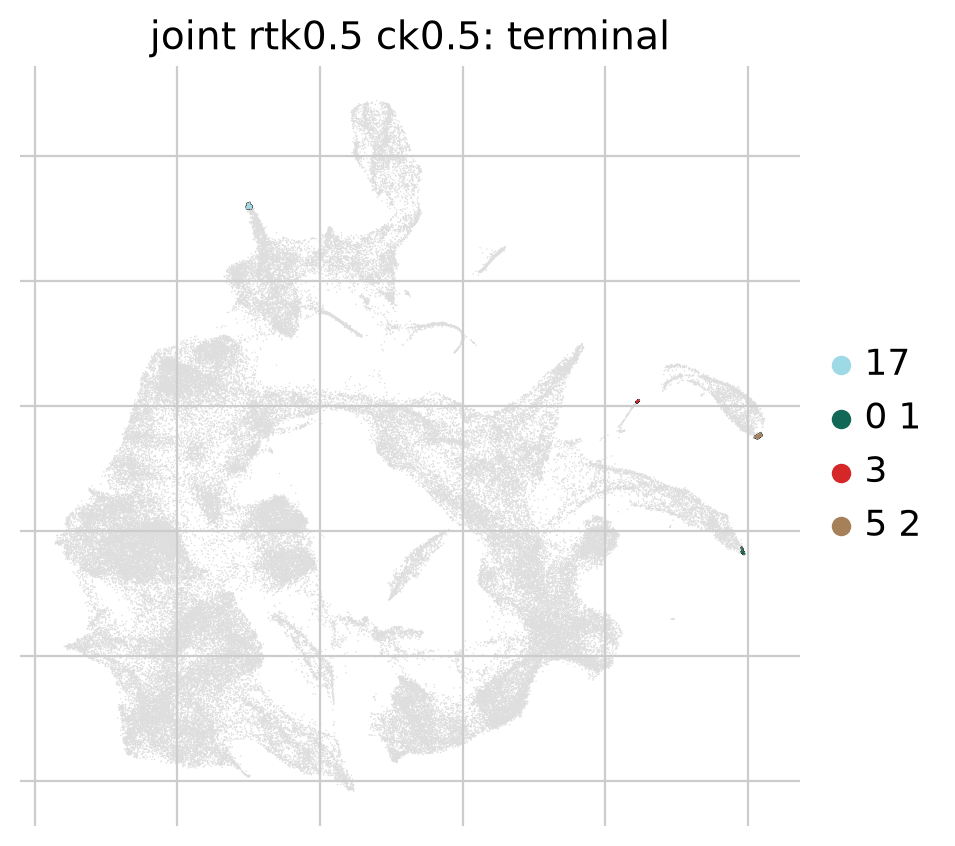

  wrote fate_joint_rtk0.5_ck0.5.csv, composition_*_joint_rtk0.5_ck0.5.csv

2/3 kernels succeeded


In [6]:
def run_estimator(name, kernel, n_states=N_STATES, cluster_key="leiden_joint"):
    print("=" * 70, f"\n{name}\n", "=" * 70, flush=True)
    g = cr.estimators.GPCCA(kernel)
    g.compute_schur(n_components=n_states + 8, method="krylov")
    g.compute_macrostates(n_states=n_states, cluster_key=cluster_key)
    # the default method="stability" keeps only macrostates above a 0.96
    # self-transition threshold; on the devbrain object none cleared it and the
    # call raised, losing all eight runs (job 61837986). top_n pins the count.
    g.predict_terminal_states(method="top_n", n_states=N_TERMINAL)
    try:
        g.predict_initial_states(n_states=1)
        init = list(g.initial_states.cat.categories)
    except Exception as e:
        print(f"  initial-state prediction failed: {e}")
        init = []
    print(f"  terminal: {list(g.terminal_states.cat.categories)}")
    print(f"  initial : {init}")

    ms = g.macrostates
    comp = (pd.crosstab(ms[~ms.isna()], adata.obs.loc[~ms.isna(), "stage"],
                        normalize="index") * 100).round(1)
    print("\n  macrostate composition by stage (%):")
    print(comp.to_string())
    ds = (pd.crosstab(ms[~ms.isna()], adata.obs.loc[~ms.isna(), "dataset"],
                      normalize="index") * 100).round(1)
    print("\n  macrostate composition by dataset (%):")
    print(ds.to_string())

    g.compute_fate_probabilities()
    g.plot_macrostates(which="all", basis=BASIS, legend_loc="right",
                       title=f"{name}: macrostates", save=f"{name}_macrostates.png")
    g.plot_macrostates(which="terminal", basis=BASIS, legend_loc="right",
                       title=f"{name}: terminal", save=f"{name}_terminal.png")
    if init:
        g.plot_macrostates(which="initial", basis=BASIS, legend_loc="right",
                           title=f"{name}: initial", save=f"{name}_initial.png")
    fate = pd.DataFrame(np.asarray(g.fate_probabilities),
                        columns=list(g.fate_probabilities.names), index=adata.obs_names)
    # write inside the function so a later run failing cannot lose earlier results
    fate.to_csv(res_dir + f"fate_{name}.csv")
    comp.to_csv(res_dir + f"composition_stage_{name}.csv")
    ds.to_csv(res_dir + f"composition_dataset_{name}.csv")
    print(f"  wrote fate_{name}.csv, composition_*_{name}.csv")

    return {"name": name, "terminal": list(g.terminal_states.cat.categories),
            "initial": init, "composition": comp, "macrostates": ms, "fate": fate}


import traceback

results = {}
for name, kern in KERNELS.items():
    try:
        results[name] = run_estimator(name, kern)
    except Exception as e:
        # print the traceback: job 61837986 swallowed these and left only an empty
        # figure behind, so finding the cause cost a whole extra run.
        print(f"!! {name} FAILED: {type(e).__name__}: {e}", flush=True)
        traceback.print_exc()
        results[name] = {"name": name, "error": f"{type(e).__name__}: {e}"}

n_ok = sum("error" not in r for r in results.values())
print(f"\n{n_ok}/{len(KERNELS)} kernels succeeded", flush=True)
if n_ok == 0:
    raise RuntimeError("every kernel failed - see the tracebacks above")

## Where does the root land?

The point of adding Brooks was to make the earliest stage reachable. If the initial state
sits in E7.0/E7.5 the bridge did its job; if it sits at E8.5+ the OT coupling is not carrying
the early cells, whatever the UMAP looks like.

In [7]:
rows = []
for name, r in results.items():
    if "error" in r:
        rows.append({"kernel": name, "status": "FAILED", "detail": r["error"][:60]})
        continue
    stage_of = {}
    for which in ("initial", "terminal"):
        for st in r[which]:
            sel = (r["macrostates"] == st).values
            if sel.any():
                stage_of[f"{which}:{st}"] = str(
                    adata.obs.loc[sel, "stage"].value_counts(normalize=True).idxmax())
    rows.append({"kernel": name, "status": "ok",
                 "initial": ", ".join(f"{k.split(':')[1]}@{v}" for k, v in stage_of.items()
                                      if k.startswith("initial")) or "none",
                 "n_terminal": len(r["terminal"])})
print(pd.DataFrame(rows).to_string(index=False))
pd.DataFrame(rows).to_csv(res_dir + "joint_kernel_overview.csv", index=False)

            kernel status                                                       detail initial  n_terminal
    joint_realtime FAILED ValueError: Discretizing leads to a cluster with `0` samples     NaN         NaN
joint_rtk0.8_ck0.2     ok                                                          NaN    none         4.0
joint_rtk0.5_ck0.5     ok                                                          NaN    none         4.0


In [8]:
import resource
print(f"peak RSS: {resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e6:.1f} GB")
print("done")       # fate_*.csv already written in run_estimator

peak RSS: 24.9 GB
done
